# Lab 01 — Tokenization

**Book section:** [0.5 Tokens and tokenization](../../book/docs/chapters/00-foundations/tokens.md).

**Goal.** Build character-, word- and byte-pair-encoding (BPE) tokenizers from scratch on the depot
instruction corpus, measure the vocabulary-size / sequence-length trade-off and out-of-vocabulary
behaviour, and compare with a production tokenizer (SmolLM2).

**Runtime:** < 1 minute on CPU. **Downloads:** SmolLM2 tokenizer files (~2 MB). **Seed:** 0.

In [1]:
import os
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

os.environ.setdefault("HF_HOME", str(Path("../../data/hf").resolve()))

from vlacourse.data.instructions import RUNNING_EXAMPLE, instruction_corpus

corpus = instruction_corpus(5000, seed=0)
train, val = corpus[:4500], corpus[4500:]
print(len(train), "training instructions, e.g.:")
for s in train[:5]:
    print("  ", s)

4500 training instructions, e.g.:
   Survey the east yard, find the red toolbox, and bring it to the inspection station.
   Stack the yellow cone on the black barrel.
   Bring the black cone to the fuel tank.
   Pick up the black panel.
   The rover, hover above the blue cable reel.


Instructions that use words the generator never produces — the kind of thing an operator will type:

In [2]:
novel = [
    "Quadrotor three, survey the east yard.",
    "Bring the red toolbox to the forklift.",
    "Inspect pallet 0x3F near bay C7-north.",
]

## 1. Character-level tokenizer
Vocabulary = every character seen in training, plus an `<unk>` id for anything else.

In [3]:
class CharTokenizer:
    def __init__(self, texts):
        self.itos = ["<unk>"] + sorted(set("".join(texts)))
        self.stoi = {c: i for i, c in enumerate(self.itos)}

    def encode(self, s):
        return [self.stoi.get(c, 0) for c in s]

    def decode(self, ids):
        return "".join(self.itos[i] for i in ids)


char_tok = CharTokenizer(train)
ids = char_tok.encode(RUNNING_EXAMPLE)
print("V =", len(char_tok.itos), "| tokens for the running example:", len(ids))
assert char_tok.decode(ids) == RUNNING_EXAMPLE

V = 35 | tokens for the running example: 83


## 2. Word-level tokenizer
Pre-tokenize with a regular expression that separates words and punctuation.

In [4]:
PRETOK = re.compile(r"\w+|[^\w\s]")


class WordTokenizer:
    def __init__(self, texts):
        self.itos = ["<unk>"] + sorted({w for t in texts for w in PRETOK.findall(t)})
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    def encode(self, s):
        return [self.stoi.get(w, 0) for w in PRETOK.findall(s)]

    def decode(self, ids):
        return " ".join(self.itos[i] for i in ids)


word_tok = WordTokenizer(train)
print("V =", len(word_tok.itos), "| tokens for the running example:", len(word_tok.encode(RUNNING_EXAMPLE)))
for s in novel:
    print(f"{s!r:45} -> {word_tok.decode(word_tok.encode(s))!r}")

V = 89 | tokens for the running example: 18
'Quadrotor three, survey the east yard.'      -> '<unk> <unk> , survey the east yard .'
'Bring the red toolbox to the forklift.'      -> 'Bring the red toolbox to the <unk> .'
'Inspect pallet 0x3F near bay C7-north.'      -> '<unk> pallet <unk> near bay <unk> <unk> north .'


Every unseen word becomes `<unk>`: the model would literally not see "forklift" or "Quadrotor". This is
the out-of-vocabulary problem that subword tokenizers solve.

## 3. Byte-pair encoding from scratch

Training (book 0.5): count adjacent symbol pairs weighted by word frequency, merge the most frequent,
repeat. We work on characters of pre-tokenized words; a leading space is attached to words (as GPT-style
tokenizers do) so that `" red"` and `"red"` can differ.

In [5]:
def pretokenize(text):
    """Split into words/punctuation, keeping a leading space on words that had one."""
    return re.findall(r" ?\w+| ?[^\w\s]", text)


def train_bpe(texts, n_merges):
    word_counts = Counter(w for t in texts for w in pretokenize(t))
    seqs = {w: list(w) for w in word_counts}
    merges = []
    for _ in range(n_merges):
        pairs = Counter()
        for w, f in word_counts.items():
            s = seqs[w]
            for a, b in zip(s, s[1:]):
                pairs[(a, b)] += f
        if not pairs:
            break
        (a, b), _ = max(pairs.items(), key=lambda kv: kv[1])   # first occurrence wins ties
        merges.append((a, b))
        for w, s in seqs.items():
            out, i = [], 0
            while i < len(s):
                if i + 1 < len(s) and s[i] == a and s[i + 1] == b:
                    out.append(a + b); i += 2
                else:
                    out.append(s[i]); i += 1
            seqs[w] = out
    return merges


class BPETokenizer:
    def __init__(self, texts, n_merges):
        self.merges = train_bpe(texts, n_merges)
        base = sorted(set("".join(texts)))
        self.itos = ["<unk>"] + base + [a + b for a, b in self.merges]
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.rank = {m: r for r, m in enumerate(self.merges)}

    def _encode_word(self, w):
        s = list(w)
        while len(s) > 1:   # apply the earliest-learned applicable merge, as in training order
            pairs = [(self.rank.get((a, b), 1e9), i) for i, (a, b) in enumerate(zip(s, s[1:]))]
            r, i = min(pairs)
            if r == 1e9:
                break
            s[i:i + 2] = [s[i] + s[i + 1]]
        return s

    def tokens(self, text):
        return [t for w in pretokenize(text) for t in self._encode_word(w)]

    def encode(self, text):
        return [self.stoi.get(t, 0) for t in self.tokens(text)]

    def decode(self, ids):
        return "".join(self.itos[i] for i in ids)

### 3.1 The worked example from the book
Word counts `drone`×5, `drones`×3, `zone`×2, `crate`×4, `crates`×2 and 6 merges.

In [6]:
toy = ["drone"] * 5 + ["drones"] * 3 + ["zone"] * 2 + ["crate"] * 4 + ["crates"] * 2
print(train_bpe(toy, 6))
assert train_bpe(toy, 6) == [("o", "n"), ("on", "e"), ("d", "r"), ("dr", "one"), ("c", "r"), ("cr", "a")]

[('o', 'n'), ('on', 'e'), ('d', 'r'), ('dr', 'one'), ('c', 'r'), ('cr', 'a')]


### 3.2 BPE on the depot corpus

In [7]:
bpe = BPETokenizer(train, n_merges=150)
print("V =", len(bpe.itos))
print("first 20 merges:", ["".join(m) for m in bpe.merges[:20]])
print(bpe.tokens(RUNNING_EXAMPLE))
assert bpe.decode(bpe.encode(RUNNING_EXAMPLE)) == RUNNING_EXAMPLE
for s in novel:
    print(f"{s!r:45} -> {[bpe.itos[i] for i in bpe.encode(s)]}")

V = 185
first 20 merges: [' t', 'he', ' the', 'on', 'in', 'ar', 'one', ' b', 'el', 'an', 've', ' c', ' r', ' to', 'ck', ' f', ' s', 'at', ' p', 'rone']
['S', 'urvey', ' the', ' east', ' yard', ',', ' f', 'ind', ' the', ' red', ' toolbox', ',', ' and', ' b', 'ring', ' it', ' to', ' the', ' inspection', ' station', '.']
'Quadrotor three, survey the east yard.'      -> ['<unk>', 'u', 'ad', 'r', 'o', 't', 'or', ' t', 'h', 'r', 'e', 'e', ',', ' survey', ' the', ' east', ' yard', '.']
'Bring the red toolbox to the forklift.'      -> ['B', 'ring', ' the', ' red', ' toolbox', ' to', ' the', ' f', 'or', 'k', 'l', 'i', 'f', 't', '.']
'Inspect pallet 0x3F near bay C7-north.'      -> ['<unk>', 'n', 's', 'p', 'e', 'c', 't', ' pallet', ' ', '<unk>', 'x', '<unk>', 'F', ' n', 'ear', ' bay', ' ', '<unk>', '<unk>', '<unk>', 'n', 'or', 't', 'h', '.']


Unseen words are no longer `<unk>`: they are spelled out of known pieces (only characters never seen in
training — e.g. digits here — become `<unk>`; byte-level BPE removes even that by starting from the 256
byte values).

### 3.3 The trade-off: vocabulary size vs. sequence length

char      V=  35  mean tokens/instruction=  46.7
bpe-0     V=  35  mean tokens/instruction=  46.7
bpe-25    V=  60  mean tokens/instruction=  30.7
bpe-50    V=  85  mean tokens/instruction=  25.2
bpe-100   V= 135  mean tokens/instruction=  19.1
bpe-200   V= 235  mean tokens/instruction=  11.1
bpe-400   V= 268  mean tokens/instruction=  10.5
word      V=  89  mean tokens/instruction=  10.5


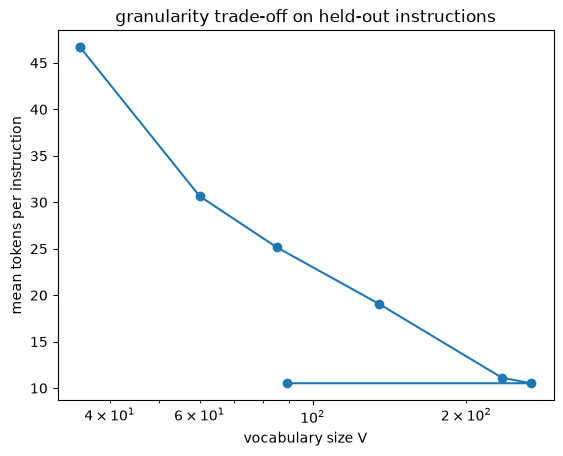

In [8]:
def mean_len(tok, texts):
    return sum(len(tok.encode(t)) for t in texts) / len(texts)


rows = [("char", len(char_tok.itos), mean_len(char_tok, val))]
for n in [0, 25, 50, 100, 200, 400]:
    t = BPETokenizer(train, n)
    rows.append((f"bpe-{n}", len(t.itos), mean_len(t, val)))
rows.append(("word", len(word_tok.itos), mean_len(word_tok, val)))
for name, V, L in rows:
    print(f"{name:8}  V={V:4d}  mean tokens/instruction={L:6.1f}")
plt.plot([r[1] for r in rows], [r[2] for r in rows], "o-")
plt.xscale("log"); plt.xlabel("vocabulary size V"); plt.ylabel("mean tokens per instruction")
plt.title("granularity trade-off on held-out instructions"); plt.show()

Attention cost grows as $T^2$ and memory of the embedding table as $V$. BPE lets you pick the point on
this curve.

## 4. Bytes
Byte-level tokenizers start from the UTF-8 bytes, so *any* string is encodable with a 256-symbol base.

In [9]:
s = "Drone→yard ✈ 5.25 m"
b = s.encode("utf-8")
print(len(s), "characters,", len(b), "bytes:", list(b))

19 characters, 23 bytes: [68, 114, 111, 110, 101, 226, 134, 146, 121, 97, 114, 100, 32, 226, 156, 136, 32, 53, 46, 50, 53, 32, 109]


## 5. A production tokenizer: SmolLM2
Byte-level BPE with a 49,152-token vocabulary, trained on web text.

In [10]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("HuggingFaceTB/SmolLM2-135M")
ids = tok(RUNNING_EXAMPLE)["input_ids"]
print(len(ids), "tokens:", [tok.decode([i]) for i in ids])
print("ids:", ids)
assert len(ids) == 19
for s in novel + ["Climb to 12.75 m and hold for 30 s."]:
    print(f"{s!r:45} -> {[tok.decode([i]) for i in tok(s)['input_ids']]}")

19 tokens: ['Sur', 'vey', ' the', ' east', ' yard', ',', ' find', ' the', ' red', ' toolbox', ',', ' and', ' bring', ' it', ' to', ' the', ' inspection', ' station', '.']
ids: [14649, 2845, 260, 6251, 13366, 28, 1042, 260, 2382, 39418, 28, 284, 2635, 357, 288, 260, 14789, 5729, 30]
'Quadrotor three, survey the east yard.'      -> ['Qu', 'ad', 'rot', 'or', ' three', ',', ' survey', ' the', ' east', ' yard', '.']
'Bring the red toolbox to the forklift.'      -> ['Bring', ' the', ' red', ' toolbox', ' to', ' the', ' for', 'kl', 'ift', '.']
'Inspect pallet 0x3F near bay C7-north.'      -> ['In', 'spect', ' pal', 'let', ' ', '0', 'x', '3', 'F', ' near', ' bay', ' C', '7', '-', 'north', '.']
'Climb to 12.75 m and hold for 30 s.'         -> ['C', 'lim', 'b', ' to', ' ', '1', '2', '.', '7', '5', ' m', ' and', ' hold', ' for', ' ', '3', '0', ' s', '.']


Observe: `Survey` at the start of a sentence (no leading space, capitalised) costs two tokens; site codes
are chopped into pieces; and SmolLM2 splits **every digit into its own token**, so `12.75` is five tokens
and the language model never sees it as one quantity.

## Exercises
1. Make the BPE byte-level: start from `s.encode("utf-8")` and merge byte sequences. Check that the novel
   instructions no longer produce `<unk>`.
2. Measure how many merges are needed before the 30 most frequent words of the corpus are single tokens.
3. Count SmolLM2 tokens for 100 random corpus instructions and for the same instructions in another
   language you know. What is the ratio, and what does it imply for latency?
4. A UAV mission prompt contains 40 GPS waypoints written as `45.123456, 9.654321`. Estimate the token
   cost with SmolLM2's tokenizer. Propose a better interface between a language model and waypoints.